# Joint RNA and ATAC analysis with bixverse

*Follows Signac's
[10x multiome vignette](https://stuartlab.org/signac/articles/pbmc_multiomic)
on the same data.*

## Intro

10x multiome measures gene expression and chromatin accessibility in the
same nuclei. This vignette takes the 10k PBMC granulocyte-sorted data set
(Cell Ranger ARC 2.0.0) through the steps of the Signac vignette: fragment
QC, multiplet calls, peak calling per cluster, TF-IDF and LSI, the weighted
nearest neighbour graph over both modalities, gene activity and label
transfer from RNA to ATAC.

ATAC lives next to the RNA in a `SingleCellsMultiModal`: a second v5 store
under `atac/` with peaks as features, TF-IDF as the norm and the genomic
coordinates in an interval index. Its cells are the RNA cells, in the same
order, so the RNA cell filter applies to both. Read the
[multi-modal vignette](multi_modal_single_cells.ipynb) first if you have not.

In [1]:
import tempfile
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed

## The data

Four files from the 10x data set page: the filtered feature barcode matrix
(RNA and Cell Ranger's peak counts in one h5), the fragment file with its
tabix index, and the GENCODE v32 annotation Cell Ranger ARC's GRCh38
reference was built from.

In [2]:
data_dir = Path.home() / "data" / "bixverse" / "atac"
h5_path = data_dir / "pbmc_granulocyte_sorted_10k_filtered_feature_bc_matrix.h5"
fragments = data_dir / "pbmc_granulocyte_sorted_10k_atac_fragments.tsv.gz"
gtf = data_dir / "gencode.v32.primary_assembly.annotation.gtf.gz"

tempdir = tempfile.TemporaryDirectory()
exp_dir = Path(tempdir.name) / "pbmc_multiome"

## Loading

The RNA comes from the `Gene Expression` rows of the h5, the ATAC from its
`Peaks` rows. `add_atac_tenx` writes the peak store for every cell of the
RNA store, in its order.

In [3]:
bv.io.load_tenx_h5(exp_dir, h5_path)
mm = bv.SingleCellsMultiModal(exp_dir)
bv.atac.add_atac_tenx(mm, h5_path)
mm

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading 10x matrix structure (shape: 11_898 cells x 180_488 features)...
  Features after type filtering: 36_601 / 180_488
First pass - gene expression statistics:


  Processed 50% of chunks (1/2)
  Processed 100% of chunks (2/2)
First pass done: 312.34ms
  Genes passing filter: 22_017 / 36_601
Second pass - cell statistics:


  Processed 50% of chunks (1/2)
  Processed 100% of chunks (2/2)
Second pass done: 373.81ms
  Cells passing filter: 11_866 / 11_898
Step 2/3: QC Results:
  Genes passing QC: 22_017 / 180_488
  Cells passing QC: 11_866 / 11_898
Step 3/3: Writing cells to CSR format...
  Processing 11_866 cells in batches of 1_000...
  Processed 1_000 / 11_866 cells
  Processed 2_000 / 11_866 cells


  Processed 3_000 / 11_866 cells
  Processed 4_000 / 11_866 cells
  Processed 5_000 / 11_866 cells
  Processed 6_000 / 11_866 cells
  Processed 7_000 / 11_866 cells
  Processed 8_000 / 11_866 cells
  Processed 9_000 / 11_866 cells


  Processed 10_000 / 11_866 cells
  Processed 11_000 / 11_866 cells
  Processed 11_866 / 11_866 cells
  Writing complete in 349.18ms
Converting the cell-based data into the gene-based format.


  Counted 23_480_367 non-zeros over 22_017 genes in 11.74ms; converting in 1 phase(s).


... (2 outputs left out)

  Processed 5_000 / 11_866 cells
  Processed 6_000 / 11_866 cells
  Processed 7_000 / 11_866 cells
  Processed 8_000 / 11_866 cells
  Processed 9_000 / 11_866 cells
  Processed 10_000 / 11_866 cells


  Processed 11_000 / 11_866 cells
  Processed 11_866 / 11_866 cells
  Writing complete in 476.09ms
  Counted 103_864_404 non-zeros over 143_887 genes in 38.47ms; converting in 1 phase(s).


  Phase 1/1: genes 0-143887, scatter 330.95ms, compress + write 658.47ms
  Conversion into gene-friendly format done: 1.06s


SingleCellsMultiModal(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpv4ary1zq/pbmc_multiome',
  cells=11866 (kept 11866), genes=22017,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
  adt=none, adt_pca=False, adt_knn=False, adt_graph=False,
  adt_embeddings=none,
  atac=AtacInfo(kind='peak', count_mode='insertion', tf_idf=False, lsi=False, lsi_dropped=[]), atac_embeddings=none, wnn=False
)

In [4]:
var = mm.var()
var.head()

gene_idx,gene_id,gene_name,feature_type,no_cells_exp
u32,str,str,str,i32
0,"""ENSG00000238009""","""AL627309.1""","""Gene Expression""",83
1,"""ENSG00000241860""","""AL627309.5""","""Gene Expression""",532
2,"""ENSG00000241599""","""AL627309.4""","""Gene Expression""",55
3,"""ENSG00000229905""","""AL669831.2""","""Gene Expression""",11
4,"""ENSG00000237491""","""LINC01409""","""Gene Expression""",631


In [5]:
mm.var(modality="atac").head()

feature_idx,feature_id,chrom,start,end
u32,str,str,i64,i64
0,"""chr1:9790-10675""","""chr1""",9790,10675
1,"""chr1:180599-181702""","""chr1""",180599,181702
2,"""chr1:191168-192093""","""chr1""",191168,192093
3,"""chr1:267565-268455""","""chr1""",267565,268455
4,"""chr1:270876-271770""","""chr1""",270876,271770


## Quality control

Per cell from the fragment file: the number of fragments, the nucleosome
signal (mono- over nucleosome-free fragments), the TSS enrichment (Signac's
fast definition), the fraction on chrM and the fraction of fragments in
peaks. Mitochondrial RNA counts come from the RNA side as usual. Cell
Ranger ARC leaves chrM out of the fragment file, so the ATAC mito fraction
is zero throughout here.

In [6]:
atac_qc = bv.atac.atac_fragment_qc(mm, fragments, gtf)
atac_qc.head()

cell_idx,atac_n_fragments,atac_nucleosome_signal,atac_tss_enrichment,atac_mito_fraction,atac_frip
u32,i64,f64,f64,f64,f64
0,44079,0.65956,6.371992,0.0,0.690272
1,17439,0.612903,5.78217,0.0,0.682293
2,14894,0.642515,5.716088,0.0,0.670639
3,1079,0.650092,7.55608,0.0,0.665894
4,6915,0.619749,5.019625,0.0,0.671656


In [7]:
symbol_col = "gene_name"
mito = var.filter(pl.col(symbol_col).str.contains("^MT-"))["gene_id"].to_list()
bv.qc.gene_set_proportions(mm, {"MT": mito}, streaming=False, verbose=False)

### Multiplets

Multiome nuclei carry two copies of each chromosome, so a locus covered by
more than two of a cell's fragments points at a second nucleus. AMULET counts
those loci per cell and tests them against a Poisson background. It needs no
clustering and no RNA. With a repeat list (`restrict_beds`) the calls are
cleaner; without one, loci in repeats inflate the counts of every cell alike.

In [8]:
amulet = bv.atac.amulet(mm, fragments)
print(f"{amulet['amulet_multiplet'].sum()} of {amulet.height} cells called multiplets")

904 of 11866 cells called multiplets


### Thresholds

Signac's thresholds for this data set on the ATAC side: `1800 < nCount <
1e5` peak counts, nucleosome signal under 2, TSS enrichment over 1. On the
RNA side we flag MAD outliers on library size and genes, and cells above
3 MADs of mitochondrial share.

In [9]:
obs = mm.obs(
    cols=[
        "cell_idx",
        "lib_size",
        "nnz",
        "MT",
        "atac_lib_size",
        "atac_nucleosome_signal",
        "atac_tss_enrichment",
        "atac_frip",
        "amulet_multiplet",
    ]
)
obs.describe()

statistic,cell_idx,lib_size,nnz,MT,atac_lib_size,atac_nucleosome_signal,atac_tss_enrichment,atac_frip,amulet_multiplet
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",11866.0,11866.0,11866.0,11866.0,11866.0,11866.0,11866.0,11866.0,11866.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",5932.5,4416.292854,1978.793781,0.102618,23070.410163,0.692511,5.825719,0.660432,0.076184
"""std""",3425.563482,2522.253034,728.254254,0.044397,14341.009399,0.169325,0.781816,0.064157,null
"""min""",0.0,251.0,119.0,0.0,96.0,0.310078,0.032583,0.157307,0.0
"""25%""",2966.0,2926.0,1519.0,0.075874,17471.0,0.607823,5.428707,0.64767,null
"""50%""",5933.0,3781.0,1827.0,0.097496,23088.0,0.66846,5.790198,0.66983,null
"""75%""",8899.0,5247.0,2314.0,0.122501,27047.0,0.731123,6.145206,0.691551,null
"""max""",11865.0,89846.0,10802.0,0.672451,660259.0,3.151007,21.245421,0.83,1.0


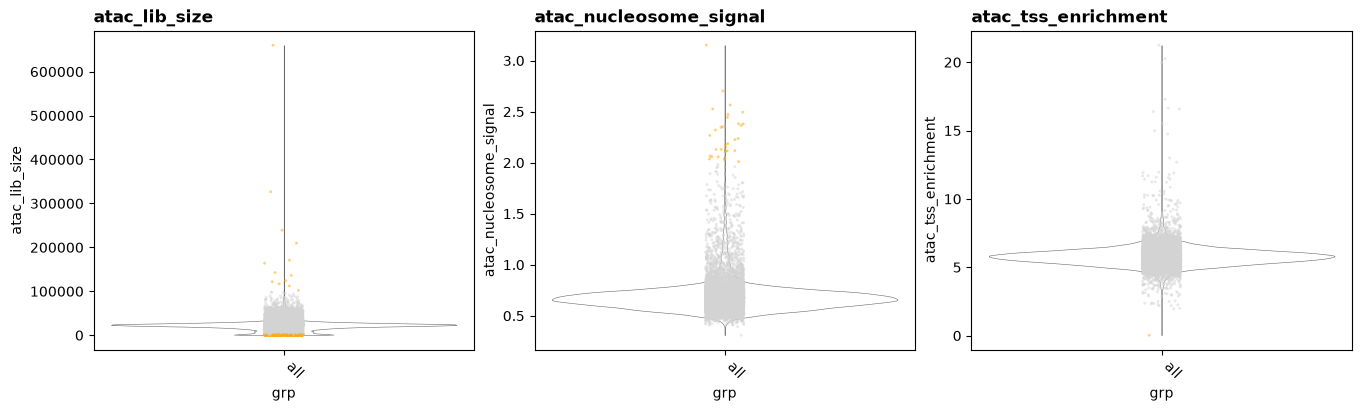

In [10]:
atac_metrics = {
    "atac_lib_size": obs["atac_lib_size"].to_numpy(),
    "atac_nucleosome_signal": obs["atac_nucleosome_signal"].to_numpy(),
    "atac_tss_enrichment": obs["atac_tss_enrichment"].to_numpy(),
}
atac_calls = bv.qc.run_cell_qc_fixed(
    atac_metrics,
    obs["cell_idx"].to_numpy(),
    {
        "atac_lib_size": {"lower": 1800, "upper": 100_000},
        "atac_nucleosome_signal": {"upper": 2},
        "atac_tss_enrichment": {"lower": 1},
    },
)
bv.pl.violin_plot(atac_calls)
plt.show()

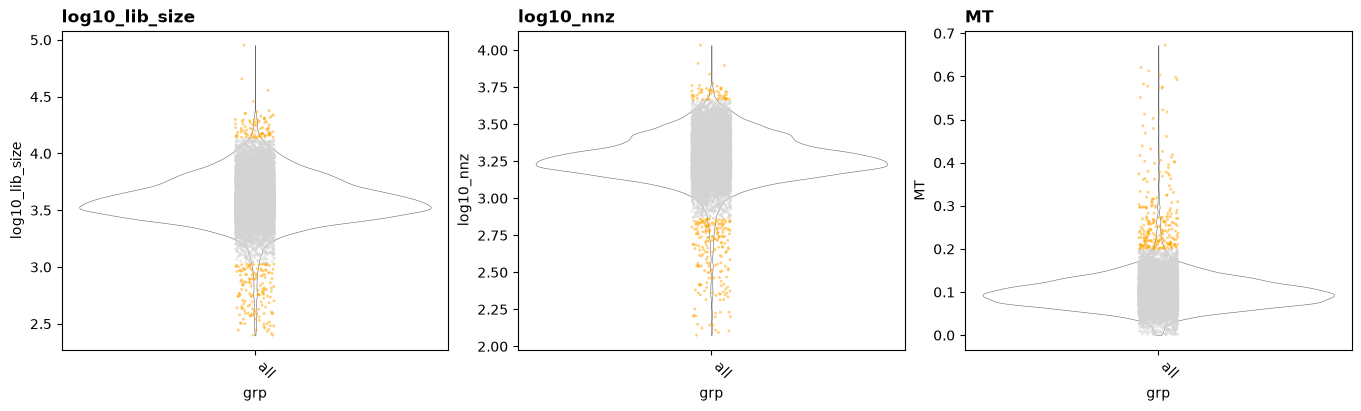

In [11]:
rna_metrics = {
    "log10_lib_size": np.log10(obs["lib_size"].to_numpy()),
    "log10_nnz": np.log10(obs["nnz"].to_numpy()),
    "MT": obs["MT"].to_numpy(),
}
directions: dict[str, Literal["twosided", "below", "above"]] = {
    "log10_lib_size": "twosided",
    "log10_nnz": "twosided",
    "MT": "above",
}
rna_calls = bv.qc.run_cell_qc(
    rna_metrics, obs["cell_idx"].to_numpy(), directions=directions, threshold=3.0
)
bv.pl.violin_plot(rna_calls)
plt.show()

In [12]:
multiplet = obs["amulet_multiplet"].to_numpy()
drop = atac_calls.combined | rna_calls.combined | multiplet
print(
    f"ATAC fails {atac_calls.combined.sum()}, RNA fails {rna_calls.combined.sum()}, "
    f"multiplets {multiplet.sum()}, dropped {drop.sum()} of {drop.size}"
)
mm.set_cells_to_keep(obs["cell_idx"].to_numpy()[~drop])

ATAC fails 546, RNA fails 450, multiplets 904, dropped 1724 of 11866


## RNA

The usual: highly variable genes, PCA, kNN, Leiden. These clusters are what
the peaks get called on below.

HVG (VST): 22_017 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 21.38ms
HVG (VST): Fitted Loess in 1.23ms
HVG (VST): Standardised variance in 363.71µs (98 gene(s) re-read for the clip)
HVG (VST): Total run time -> 23.01ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 19.81ms
Sparse PCA: finished the data preparations in 2.51ms


Sparse PCA: finished calculations in 455.05ms
Sparse PCA: total run time -> 477.51ms
Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 22.48ms
Generated KmKnn index: 22.99ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 22.28ms
Queried KmKnn index: 22.35ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 15.64ms


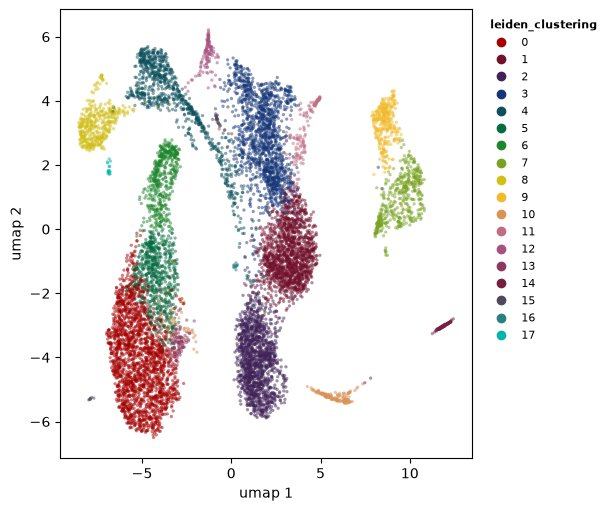

In [13]:
bv.pp.find_hvg(mm, hvg_no=2000)
bv.pp.calculate_pca(mm, no_pcs=50)
bv.graph.find_neighbours(mm, no_embd_to_use=30)
bv.graph.find_clusters(mm, res=0.8)
bv.embed.umap(mm, no_embd_to_use=30)
bv.pl.embedding_plot(mm, "umap", "leiden_clustering", discrete=True, point_size=0.5)
plt.show()

## Peaks

Cell Ranger calls peaks on all cells pooled, which under-calls rare
populations. As in the Signac vignette we call them per cluster with a native
port of MACS3 `callpeak` (Signac's settings: `--nomodel --extsize 200
--shift -100`), merge the per cluster peaks and count the fragments against
the merged set. The new store replaces the Cell Ranger one.

In [14]:
cr_peaks = mm.var(modality="atac").height
peaks = bv.atac.call_peaks(mm, fragments, group_by="leiden_clustering")
print(f"Cell Ranger peaks: {cr_peaks}, merged per-cluster peaks: {peaks.height}")
peaks.head()

Cell Ranger peaks: 143887, merged per-cluster peaks: 182835


chrom,start,end,peak_called_in
str,u32,u32,str
"""GL000194.1""",28212,28530,"""1,2,7,15"""
"""GL000194.1""",101196,101642,"""4,7,8,12,14,17"""
"""GL000194.1""",114776,115144,"""0,1,2,3,4,5,6,7,8,9,12,14"""
"""GL000195.1""",22471,22912,"""0"""
"""GL000195.1""",24051,24297,"""0"""


In [15]:
peaks = peaks.filter(pl.col("chrom").str.contains(r"^chr[0-9XY]+$"))
bv.atac.add_atac_fragments(mm, fragments, peaks=peaks)
mm.var(modality="atac").head()

  Counted 105_456_841 non-zeros over 182_793 genes in 50.68ms; converting in 1 phase(s).


  Phase 1/1: genes 0-182793, scatter 379.13ms, compress + write 645.86ms
  Conversion into gene-friendly format done: 1.11s


feature_idx,feature_id,chrom,start,end
u32,str,str,i64,i64
0,"""chr1:10051-10426""","""chr1""",10051,10426
1,"""chr1:96471-96707""","""chr1""",96471,96707
2,"""chr1:180774-181036""","""chr1""",180774,181036
3,"""chr1:181334-181555""","""chr1""",181334,181555
4,"""chr1:191425-191689""","""chr1""",191425,191689


## TF-IDF and LSI

TF-IDF over the kept cells (Signac method 1), the most accessible peaks, then
a truncated SVD. The first component tracks sequencing depth; we look before
dropping it.

In [16]:
bv.atac.run_tfidf(mm)
top = bv.atac.find_top_features(mm, min_cutoff="q5")
print(f"{top.size} top peaks")
bv.atac.calculate_lsi(mm, n_comp=50)
bv.atac.get_lsi_depth_cor(mm).head(5)

174312 top peaks


component,depth_cor,dropped
i64,f64,bool
1,0.921128,true
2,0.154062,false
3,0.181267,false
4,-0.046525,false
5,0.137174,false


Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 23.19ms
Generated KmKnn index: 24.03ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 37.03ms
Queried KmKnn index: 37.09ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 11.94ms


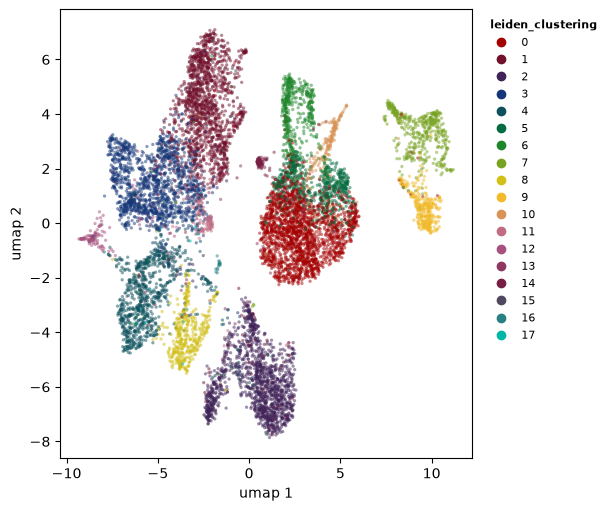

In [17]:
bv.graph.find_neighbours(mm, embd_to_use="lsi", modality="atac")
bv.embed.umap(mm, embd_to_use="lsi", modality="atac")
bv.pl.embedding_plot(
    mm, "umap", "leiden_clustering", discrete=True, embd_modality="atac", point_size=0.5
)
plt.show()

The RNA clusters should stay together on the ATAC UMAP: the two modalities
come from the same nuclei.

## Weighted nearest neighbours

WNN fuses the RNA PCA and the ATAC LSI per cell, weighting each by how well
it predicts the cell's neighbourhood.

Running WNN graph generation.


Running the kNN generation for modality 1 with 200 neighbours.
Running the kNN generation for modality 2 with 200 neighbours.


Built the Snn { similarity: Jaccard, prune: 0.0, rescue: false } graph: 24.45ms
Built the Snn { similarity: Jaccard, prune: 0.0, rescue: false } graph: 15.35ms
WNN: per-modality SNN built in 41.74ms
WNN: modality weights in 14.54ms
WNN: graph constructed in 22.89ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 15.72ms


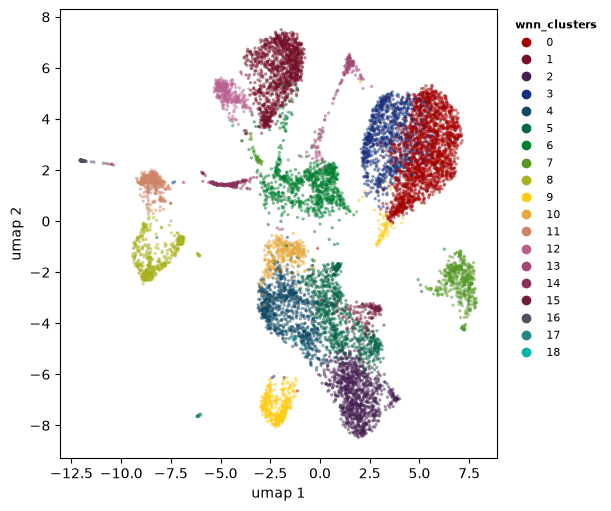

In [18]:
bv.mm.generate_wnn_graph(
    mm,
    modality_2="atac",
    embd_to_use_2="lsi",
    no_embd_to_use_1=50,
)
bv.graph.find_clusters(mm, modality="wnn", name="wnn_clusters", res=0.8)
bv.embed.umap(mm, modality="wnn")
bv.pl.embedding_plot(
    mm,
    "umap",
    "wnn_clusters",
    discrete=True,
    embd_modality="wnn",
    point_size=0.5,
)
plt.show()

In [19]:
weights = bv.mm.get_wnn_weights(mm)
weights.head()

cell_id,weight_modality_1,weight_modality_2
str,f64,f64
"""AAACAGCCAATCCCTT-1""",0.281913,0.718087
"""AAACAGCCAATGCGCT-1""",0.385914,0.614086
"""AAACAGCCACCAACCG-1""",0.608392,0.391608
"""AAACAGCCAGGATAAC-1""",0.472405,0.527595
"""AAACAGCCAGTTTACG-1""",0.420725,0.579275


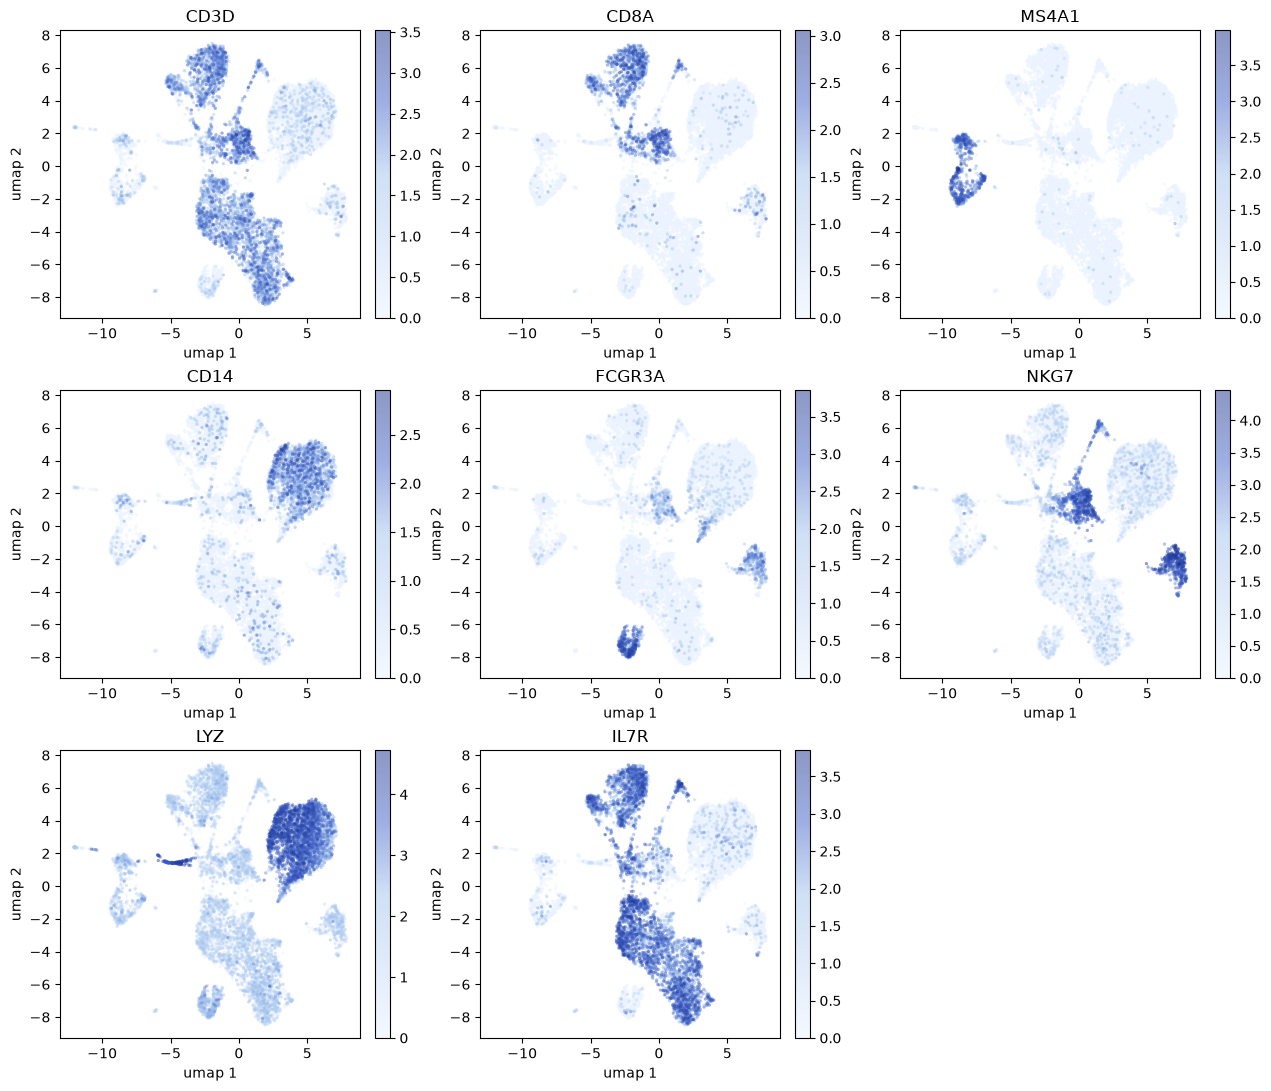

In [20]:
symbol_to_id = dict(zip(var[symbol_col], var["gene_id"], strict=False))
markers = ["CD3D", "CD8A", "MS4A1", "CD14", "FCGR3A", "NKG7", "LYZ", "IL7R"]
bv.pl.feature_plot(
    mm,
    [symbol_to_id[g] for g in markers],
    "umap",
    feature_labels={symbol_to_id[g]: g for g in markers},
    embd_modality="wnn",
    point_size=0.5,
)
plt.show()

## Gene activity and label transfer

Gene activity counts fragments over gene body plus 2 kb upstream (Signac's
`GeneActivity`) into a gene by cell store of its own. It is the shared
feature space for moving labels from an RNA reference onto ATAC cells. With
paired data we know the answer: the RNA clusters of the same nuclei. Transfer
them through gene activity and the ATAC LSI and count how many come back.

In [21]:
ga = bv.atac.gene_activity(mm, fragments, gtf)
ga.var().head()

  Counted 85_581_190 non-zeros over 19_675 genes in 29.44ms; converting in 1 phase(s).


  Phase 1/1: genes 0-19675, scatter 131.49ms, compress + write 167.00ms
  Conversion into gene-friendly format done: 338.48ms


gene_idx,gene_id,gene_name,chrom,start,end,no_cells_exp
u32,str,str,str,i64,i64,i32
0,"""ENSG00000186092""","""OR4F5""","""chr1""",63418,71585,7
1,"""ENSG00000284733""","""OR4F29""","""chr1""",450702,453697,0
2,"""ENSG00000284662""","""OR4F16""","""chr1""",685678,688673,0
3,"""ENSG00000187634""","""SAMD11""","""chr1""",921927,944581,3564
4,"""ENSG00000188976""","""NOC2L""","""chr1""",944202,961309,6113


In [22]:
transfer = bv.annotate.transfer_labels_seurat(
    mm,
    ga,
    "leiden_clustering",
    mm.atac_cache.embeddings["lsi"],
)
truth = mm.obs(cols=["leiden_clustering"], filtered=True)["leiden_clustering"]
predicted = transfer["predicted_leiden_clustering"].cast(pl.String)
agree = (predicted == truth.cast(pl.String)).mean()
print(f"transferred label equals the RNA cluster for {agree:.1%} of cells")

transferred label equals the RNA cluster for 85.8% of cells


## Differential accessibility

The marker functions take `modality="atac"` and test peaks instead of
genes: here every WNN cluster against the rest, Wilcoxon on the TF-IDF
layer. With replicates, `bv.de.pseudobulk_dge(..., modality="atac")` runs
edgeR on summed peak counts instead.

In [23]:
da = bv.de.find_all_markers(mm, "wnn_clusters", modality="atac", verbose=0)
da.filter(pl.col("fdr") < 0.05).group_by("grp").len().sort("grp")

grp,len
i32,u32
0,25002
1,17457
2,19299
3,27155
4,19082
…,…
14,33993
15,10649
16,30214


In [24]:
da.filter(pl.col("fdr") < 0.05).sort("lfc", descending=True).head(10)

grp,gene_id,lfc,prop1,prop2,z_scores,p_values,fdr
i32,str,f64,f64,f64,f64,f64,f64
18,"""chrY:13703699-13704039""",3.532286,0.571429,0.000493,50.710489,0.0,0.0
17,"""chr13:106865910-106866373""",2.834733,0.5,0.000198,63.650567,0.0,0.0
17,"""chr11:124276230-124276559""",2.797504,0.5,0.000296,60.67494,0.0,0.0
17,"""chr5:27171850-27172386""",2.785707,0.5,0.000099,67.096908,0.0,0.0
17,"""chr2:16438763-16439060""",2.773415,0.5,0.000099,67.091937,0.0,0.0
16,"""chr2:1822715-1823730""",2.660043,0.729167,0.000697,81.846373,0.0,0.0
17,"""chr21:46320449-46320734""",2.549098,0.625,0.004246,34.412619,8.1641e-260,3.3656e-257
17,"""chr22:32880978-32881651""",2.516685,0.6875,0.008098,28.49983,5.8857e-179,1.1811e-176
17,"""chr13:93228458-93228760""",2.501886,0.4375,0.000296,55.67833,0.0,0.0
